#  Praktikum Data Mining: Evaluasi Model Klasifikasi
###  Studi Kasus: Deteksi Transaksi Fraud pada Pembayaran Digital

---

##  1. Tujuan Praktikum
Pada praktikum ini, kita akan mempelajari evaluasi kinerja model klasifikasi secara mendalam, khususnya pada kasus dataset tidak seimbang (*imbalanced dataset*) yang mencerminkan kondisi riil di industri perbankan dan fintech.

**Indikator Capaian:**
1.  Mengidentifikasi elemen dasar Confusion Matrix: **True Positive (TP)**, **True Negative (TN)**, **False Positive (FP)**, dan **False Negative (FN)**.
2.  Menghitung metrik evaluasi secara manual: **Accuracy**, **Precision**, **Recall**, dan **F1-Score**.
3.  Melatih model *Decision Tree* dan mengevaluasi prediksinya menggunakan pustaka **scikit-learn**.
4.  Memvisualisasikan **Confusion Matrix** serta menginterpretasikan kesalahan prediksi.
5.  Memahami fenomena **Accuracy Paradox** pada dataset tidak seimbang (*class imbalance*).
6.  Melakukan eksperimen penyetelan ambang batas (*threshold tuning*) untuk menyeimbangkan *trade-off* antara Precision dan Recall.



---
##  2. Landasan Teori & Konsep Kunci

### 2.1 Mengapa Akurasi Saja Dapat Menyesatkan?
Dalam skenario deteksi penipuan (*fraud detection*), serangan siber, atau diagnosis penyakit langka, jumlah kelas positif (minoritas) sangat sedikit dibandingkan kelas normal.
- Misalkan dari **1.000 transaksi**, terdapat **990 transaksi normal (99%)** dan **10 transaksi fraud (1%)**.
- Jika kita membuat model "bodoh" yang selalu menebak "Normal" untuk setiap transaksi:
  $$\text{Akurasi} = \frac{990}{1000} = 99.0\%$$
- Model ini memperoleh akurasi fantastis **99%**, namun **gagal menangkap satu pun tindak kejahatan fraud (Recall = 0%)**.
- Inilah yang disebut dengan **The Accuracy Paradox**. Untuk itu, kita membutuhkan metrik turunan dari **Confusion Matrix**.

---

### 2.2 Anatomi Confusion Matrix (Matriks Kebingungan)

Confusion matrix merangkum kecocokan antara label aktual (*ground truth*) dengan label prediksi model:

| Kondisi Aktual \ Hasil Prediksi | Prediksi Fraud (1) | Prediksi Normal (0) |
| :--- | :---: | :---: |
| **Aktual Fraud (1)** | **True Positive (TP)**<br>*(Fraud benar terdeteksi)* | **False Negative (FN)**<br>*(Fraud lolos / terlewat)* |
| **Aktual Normal (0)** | **False Positive (FP)**<br>*(Alarm palsu / normal diblokir)* | **True Negative (TN)**<br>*(Normal benar dikenali)* |

>  **Catatan Penting Scikit-Learn:**
> Pustaka `scikit-learn` dengan parameter `labels=[0, 1]` menghasilkan matriks 2x2 dengan urutan baris & kolom:
> `[[TN, FP], [FN, TP]]`
> Nilai skalar dapat diekstrak secara berurutan menggunakan method `.ravel()`.

---

### 2.3 Formula Metrik Evaluasi

1. **Accuracy (Akurasi):**
   $$\text{Accuracy} = \frac{TP + TN}{TP + TN + FP + FN}$$
   *Proporsi seluruh tebakan yang benar dari keseluruhan sampel data.*

2. **Precision (Presisi):**
   $$\text{Precision} = \frac{TP}{TP + FP}$$
   *Tingkat ketepatan alarm: Dari semua transaksi yang dituduh fraud oleh model, berapa persen yang benar-benar fraud?*

3. **Recall / Sensitivity (Daya Tangkap):**
   $$\text{Recall} = \frac{TP}{TP + FN}$$
   *Tingkat sensitivitas deteksi: Dari seluruh transaksi fraud aktual di lapangan, berapa persen yang berhasil dijaring model?*

4. **F1-Score:**
   $$\text{F1-Score} = 2 \times \frac{\text{Precision} \times \text{Recall}}{\text{Precision} + \text{Recall}}$$
   *Rata-rata harmonik (harmonic mean) antara Precision dan Recall, memberi skor penyeimbang ketika salah satu metrik timpang.*

---

### 2.4 Contoh Perhitungan Manual (Sesuai Modul)
Misalkan dari **100 transaksi** pada data uji diperoleh:
- $\text{TP} = 15$
- $\text{TN} = 75$
- $\text{FP} = 5$
- $\text{FN} = 5$

**Perhitungan:**
- $\text{Accuracy} = \frac{15 + 75}{100} = \frac{90}{100} = 90.0\%$
- $\text{Precision} = \frac{15}{15 + 5} = \frac{15}{20} = 75.0\%$
- $\text{Recall} = \frac{15}{15 + 5} = \frac{15}{20} = 75.0\%$
- $\text{F1-Score} = 2 \times \frac{0.75 \times 0.75}{0.75 + 0.75} = 75.0\%$

**Interpretasi:** Terdapat 5 transaksi fraud yang luput dari pengawasan (FN) dan 5 transaksi pelanggan normal yang menerima alarm palsu (FP).


---
## 🧪 3. Langkah-Langkah Praktikum

### 4.1 Menyiapkan Dataset Sintetis
Kita membangkitkan data sintetis **500 transaksi pembayaran digital** secara deterministik menggunakan generator acak `np.random.default_rng(42)`.
Fitur-fitur transaksi:
- `amount`: Nominal transaksi (mengikuti distribusi log-normal).
- `hour`: Waktu jam transaksi ($0 - 23$).
- `new_device`: Indikator login perangkat baru ($1 = \text{ya}, 0 = \text{tidak}$).
- `foreign_ip`: Indikator koneksi IP luar negeri ($1 = \text{ya}, 0 = \text{tidak}$).
- `isFraud`: Label target biner ($1 = \text{fraud}, 0 = \text{normal}$).


In [1]:
import os
import warnings
# Mengatur konfigurasi cache & peringatan agar output bersih
os.environ['MPLCONFIGDIR'] = '/tmp/matplotlib'
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd

# Inisialisasi generator acak deterministik (seed 42)
rng = np.random.default_rng(42)
n = 500

# 1. Pembangkitan Fitur Transaksi
amount = rng.lognormal(mean=5.0, sigma=1.0, size=n)
hour = rng.integers(0, 24, n)
new_device = rng.binomial(1, 0.25, n)
foreign_ip = rng.binomial(1, 0.12, n)

# 2. Formula Probabilitas Fraud (Logistic Score Function)
score = -4.5 + 0.45 * (amount > 300) + 1.1 * new_device + 1.5 * foreign_ip + 0.7 * (hour < 5)
prob = 1 / (1 + np.exp(-score))
isFraud = rng.binomial(1, prob)

# 3. Membentuk DataFrame
df = pd.DataFrame({
    'amount': amount.round(2),
    'hour': hour,
    'new_device': new_device,
    'foreign_ip': foreign_ip,
    'isFraud': isFraud
})

print("=== 5 Baris Pertama Dataset ===")
display(df.head())

print("\n=== Distribusi Kelas Target (isFraud) ===")
distribusi = df['isFraud'].value_counts()
persentase = (df['isFraud'].value_counts(normalize=True) * 100).round(2)
ringkasan_kelas = pd.DataFrame({
    'Jumlah Sampel': distribusi,
    'Persentase (%)': persentase
})
ringkasan_kelas.index = ['Normal (0)', 'Fraud (1)']
display(ringkasan_kelas)


=== 5 Baris Pertama Dataset ===


,amount,hour,new_device,foreign_ip,isFraud
0,201.28,9,0,0,0
1,52.46,8,0,0,0
2,314.33,17,1,0,0
3,380.15,3,0,0,0
4,21.09,5,1,0,0



=== Distribusi Kelas Target (isFraud) ===


,Jumlah Sampel,Persentase (%)
Normal (0),484,96.8
Fraud (1),16,3.2


---
### 4.2 Membagi Data dan Melatih Model
- Dataset dibagi menjadi **70% Data Latih (350 sampel)** dan **30% Data Uji (150 sampel)**.
- Parameter `stratify=y` sangat krusial: menjaga rasio kelas minoritas (fraud) tetap sama persis di data latih dan data uji.
- Model menggunakan **Decision Tree Classifier** (`max_depth=4`, `random_state=42`).
- Parameter `class_weight='balanced'` memberikan bobot lebih berat pada kelas minoritas agar algoritma pohon tidak mengabaikan kelas fraud.


In [2]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier

# Pemisahan fitur (X) dan target (y)
X = df.drop(columns='isFraud')
y = df['isFraud']

# Pembagian data latih (70%) dan data uji (30%) dengan stratifikasi
X_train, X_test, y_train, y_test = train_test_split(
    X, y, 
    test_size=0.30, 
    random_state=42, 
    stratify=y
)

# Inisialisasi Decision Tree dengan class_weight balanced
model = DecisionTreeClassifier(
    max_depth=4, 
    class_weight='balanced', 
    random_state=42
)
model.fit(X_train, y_train)

# Melakukan prediksi pada data uji (X_test)
y_pred = model.predict(X_test)

print(f"Jumlah sampel Data Latih : {len(X_train)}")
print(f"Jumlah sampel Data Uji   : {len(X_test)}")
print(f"Proporsi fraud di Data Uji: {y_test.sum()} dari {len(y_test)} transaksi ({(y_test.mean()*100):.1f}%)")


Jumlah sampel Data Latih : 350
Jumlah sampel Data Uji   : 150
Proporsi fraud di Data Uji: 5 dari 150 transaksi (3.3%)


---
### 4.3 Menghitung Confusion Matrix
Kita membandingkan label aktual (`y_test`) dengan hasil prediksi (`y_pred`).
Dengan parameter `labels=[0, 1]`, susunan output matriks adalah:
$$\begin{bmatrix} TN & FP \\ FN & TP \end{bmatrix}$$
Fungsi `cm.ravel()` mengekstrak nilai-nilai tersebut ke variabel `tn`, `fp`, `fn`, dan `tp`.


In [ ]:
from sklearn.metrics import confusion_matrix

# Menghitung confusion matrix [0: Normal, 1: Fraud]
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
tn, fp, fn, tp = cm.ravel()

print("=== Confusion Matrix Array ===")
print(cm)
print("\n=== Ekstraksi Nilai Dasar ===")
print(f"True Positive  (TP) : {tp:<3} -> Transaksi fraud yang berhasil dideteksi sistem")
print(f"True Negative  (TN) : {tn:<3} -> Transaksi normal yang berhasil diidentifikasi normal")
print(f"False Positive (FP) : {fp:<3} -> Transaksi normal yang salah dituduh fraud (Alarm Palsu)")
print(f"False Negative (FN) : {fn:<3} -> Transaksi fraud yang lolos dan tidak terdeteksi")

=== Confusion Matrix Array ===
[[113  32]
 [  3   2]]

=== Ekstraksi Nilai Dasar ===
True Positive  (TP) : 2   -> Transaksi fraud yang berhasil dideteksi sistem
True Negative  (TN) : 113 -> Transaksi normal yang berhasil diidentifikasi normal
False Positive (FP) : 32  -> Transaksi normal yang salah dituduh fraud (Alarm Palsu)
False Negative (FN) : 3   -> Transaksi fraud yang lolos dan tidak terdeteksi


---
### 4.4 Perhitungan Manual dan Verifikasi dengan Scikit-Learn
Kita menghitung metrik evaluasi secara manual menggunakan rumus dasar dari variabel `tp, tn, fp, fn`, kemudian membandingkan hasilnya dengan fungsi bawaan `sklearn.metrics`.


In [4]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# 1. Perhitungan Manual
acc_manual = (tp + tn) / (tp + tn + fp + fn)
prec_manual = tp / (tp + fp) if (tp + fp) else 0.0
rec_manual = tp / (tp + fn) if (tp + fn) else 0.0
f1_manual = (2 * prec_manual * rec_manual) / (prec_manual + rec_manual) if (prec_manual + rec_manual) else 0.0

# 2. Perhitungan via Fungsi Scikit-Learn
acc_sklearn = accuracy_score(y_test, y_pred)
prec_sklearn = precision_score(y_test, y_pred, zero_division=0)
rec_sklearn = recall_score(y_test, y_pred, zero_division=0)
f1_sklearn = f1_score(y_test, y_pred, zero_division=0)

# 3. Membuat Tabel Komparasi
df_komparasi = pd.DataFrame({
    'Metrik': ['Accuracy', 'Precision', 'Recall', 'F1-Score'],
    'Perhitungan Manual': [acc_manual, prec_manual, rec_manual, f1_manual],
    'Scikit-Learn': [acc_sklearn, prec_sklearn, rec_sklearn, f1_sklearn]
})
df_komparasi['Selisih'] = (df_komparasi['Perhitungan Manual'] - df_komparasi['Scikit-Learn']).abs()

print("=== Verifikasi Perhitungan Metrik ===")
display(df_komparasi.round(4))


=== Verifikasi Perhitungan Metrik ===


,Metrik,Perhitungan Manual,Scikit-Learn,Selisih
0,Accuracy,0.7667,0.7667,0.0
1,Precision,0.0588,0.0588,0.0
2,Recall,0.4000,0.4000,0.0
3,F1-Score,0.1026,0.1026,0.0


---
### 4.5 Visualisasi Confusion Matrix
Visualisasi heatmap memudahkan audiens memahami proporsi prediksi benar vs salah secara visual.


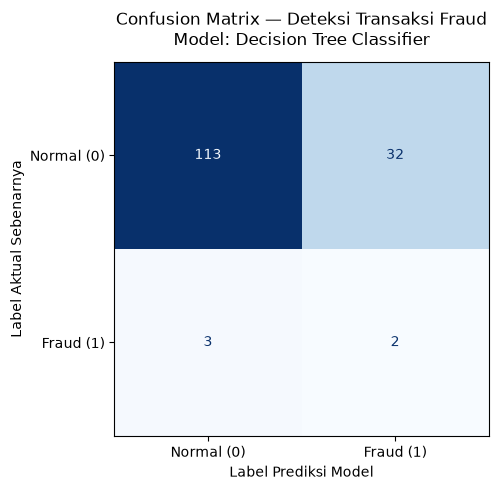

In [5]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

fig, ax = plt.subplots(figsize=(6, 5))
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm, 
    display_labels=['Normal (0)', 'Fraud (1)']
)
disp.plot(cmap='Blues', values_format='d', ax=ax, colorbar=False)

plt.title('Confusion Matrix — Deteksi Transaksi Fraud\nModel: Decision Tree Classifier', fontsize=12, pad=12)
plt.xlabel('Label Prediksi Model', fontsize=10)
plt.ylabel('Label Aktual Sebenarnya', fontsize=10)
plt.tight_layout()
plt.show()


---
### 4.6 Interpretasi Praktis & Dampak Bisnis

Dalam industri perbankan dan fintech, setiap jenis kesalahan prediksi membawa konsekuensi finansial dan operasional yang berbeda:

1. **False Negative (FN) — Fraud Lolos Tidak Terdeteksi:**
   - 💸 **Dampak:** Kerugian finansial langsung, tuntutan penggantian dana nasabah (*chargeback liability*), denda regulasi, dan hilangnya kepercayaan publik terhadap keamanan sistem perbankan.
   - 🚨 **Tingkat Kritis:** **Sangat Tinggi**. Sistem harus mengutamakan nilai **Recall tinggi** untuk menekan FN sekecil mungkin.

2. **False Positive (FP) — Normal Salah Dituduh Fraud (Alarm Palsu):**
   - 😤 **Dampak:** Transaksi sah nasabah diblokir saat berbelanja (*customer friction*), potensi nasabah berpindah ke bank/dompet digital pesaing, dan beban biaya operasional tim *Customer Care* untuk memproses pembukaan blokir.
   - ⚠️ **Tingkat Kritis:** **Sedang**. Kenaikan FP menurunkan nilai **Precision**.

> 📌 **Prinsip Keputusan:**
> "Lebih baik menanyakan konfirmasi OTP tambahan kepada 10 nasabah sah (FP), daripada membiarkan 1 pencuri membobol rekening nasabah tanpa terdeteksi (FN)."


---
### 4.7 Eksperimen: Baseline Model "Semua Normal" (*The Accuracy Paradox*)

Untuk membuktikan kelemahan metrik Accuracy pada data imbalanced, kita membandingkan Decision Tree dengan **Model Baseline Naive** yang selalu menebak label $0$ (Normal) tanpa menganalisis fitur sama sekali.


In [6]:
from sklearn.metrics import classification_report

# Model baseline: selalu menebak 0 (Normal) untuk seluruh data uji
baseline_pred = np.zeros(len(y_test), dtype=int)

print("="*65)
print(f"AKURASI MODEL BASELINE (Semua Ditebak Normal) : {accuracy_score(y_test, baseline_pred):.4f} ({accuracy_score(y_test, baseline_pred)*100:.2f}%)")
print(f"AKURASI MODEL DECISION TREE                  : {accuracy_score(y_test, y_pred):.4f} ({accuracy_score(y_test, y_pred)*100:.2f}%)")
print("="*65)

print("\n[1] Classification Report: BASELINE (Semua Ditebak Normal)")
print(classification_report(y_test, baseline_pred, target_names=['Normal (0)', 'Fraud (1)'], labels=[0, 1], zero_division=0))

print("[2] Classification Report: DECISION TREE")
print(classification_report(y_test, y_pred, target_names=['Normal (0)', 'Fraud (1)'], labels=[0, 1], zero_division=0))


AKURASI MODEL BASELINE (Semua Ditebak Normal) : 0.9667 (96.67%)
AKURASI MODEL DECISION TREE                  : 0.7667 (76.67%)

[1] Classification Report: BASELINE (Semua Ditebak Normal)
              precision    recall  f1-score   support

  Normal (0)       0.97      1.00      0.98       145
   Fraud (1)       0.00      0.00      0.00         5

    accuracy                           0.97       150
   macro avg       0.48      0.50      0.49       150
weighted avg       0.93      0.97      0.95       150

[2] Classification Report: DECISION TREE
              precision    recall  f1-score   support

  Normal (0)       0.97      0.78      0.87       145
   Fraud (1)       0.06      0.40      0.10         5

    accuracy                           0.77       150
   macro avg       0.52      0.59      0.48       150
weighted avg       0.94      0.77      0.84       150



#### 🔍 Analisis The Accuracy Paradox:
- **Model Baseline** mencatatkan akurasi sebesar **96.67%**, tampak sangat impresif jika hanya melihat angka akurasi.
- Namun, perhatikan **Recall kelas Fraud (1) pada Baseline adalah 0.00 (0%)**! Model ini membiarkan seluruh tindak kejahatan lolos 100%.
- Sebaliknya, **Decision Tree** memiliki akurasi lebih rendah (**76.67%**), namun berhasil mendeteksi transaksi fraud dengan **Recall 40%**.
- **Kesimpulan:** Pada dataset dengan kelas tidak seimbang, akurasi tinggi bisa menjadi ilusi yang berbahaya. Metrik **Recall, Precision, dan F1-Score** jauh lebih relevan.


---
### 4.8 Eksperimen: Pengaruh Ambang Batas Prediksi (*Threshold Tuning*)

Secara default, fungsi klasifikasi menggunakan ambang batas (*threshold*) probabilitas $0.5$ ($50\%$).
Kita dapat menggeser ambang batas ini sesuai kebutuhan strategi bisnis:
- **Threshold diturunkan ($0.2$):** Model lebih agresif mencurigai fraud $\rightarrow$ **Recall naik** (lebih sedikit fraud yang lolos), namun **Precision turun** (alarm palsu meningkat).
- **Threshold dinaikkan ($0.7$):** Model sangat berhati-hati $\rightarrow$ **Precision naik**, namun **Recall turun** (risiko fraud lolos meningkat).


In [7]:
# Mengambil probabilitas prediksi untuk kelas positif (Fraud = 1)
idx_fraud_class = list(model.classes_).index(1)
y_prob = model.predict_proba(X_test)[:, idx_fraud_class]

threshold_candidates = [0.2, 0.4, 0.5, 0.7]
eval_results = []

for t in threshold_candidates:
    pred_custom = (y_prob >= t).astype(int)
    cm_t = confusion_matrix(y_test, pred_custom, labels=[0, 1])
    tn_t, fp_t, fn_t, tp_t = cm_t.ravel()
    
    p = precision_score(y_test, pred_custom, zero_division=0)
    r = recall_score(y_test, pred_custom, zero_division=0)
    f1 = f1_score(y_test, pred_custom, zero_division=0)
    
    eval_results.append({
        'Threshold': t,
        'TP': tp_t,
        'FP': fp_t,
        'FN': fn_t,
        'TN': tn_t,
        'Precision': round(p, 3),
        'Recall': round(r, 3),
        'F1-Score': round(f1, 3)
    })

df_threshold = pd.DataFrame(eval_results)
print("=== Tabel Pengaruh Threshold terhadap Performa Model ===")
display(df_threshold)


=== Tabel Pengaruh Threshold terhadap Performa Model ===


,Threshold,TP,FP,FN,TN,Precision,Recall,F1-Score
0,0.2,2,32,3,113,0.059,0.4,0.103
1,0.4,2,32,3,113,0.059,0.4,0.103
2,0.5,2,32,3,113,0.059,0.4,0.103
3,0.7,1,17,4,128,0.056,0.2,0.087


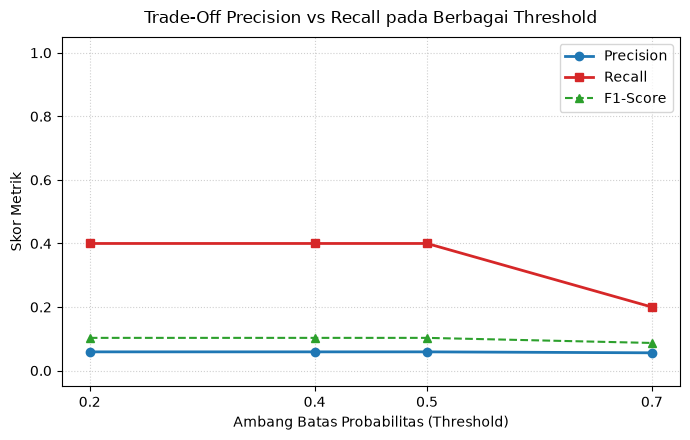

In [8]:
# Visualisasi Trade-Off Precision vs Recall berdasarkan Threshold
plt.figure(figsize=(7, 4.5))
plt.plot(df_threshold['Threshold'], df_threshold['Precision'], marker='o', linewidth=2, label='Precision', color='#1f77b4')
plt.plot(df_threshold['Threshold'], df_threshold['Recall'], marker='s', linewidth=2, label='Recall', color='#d62728')
plt.plot(df_threshold['Threshold'], df_threshold['F1-Score'], marker='^', linestyle='--', linewidth=1.5, label='F1-Score', color='#2ca02c')

plt.title('Trade-Off Precision vs Recall pada Berbagai Threshold', fontsize=12, pad=10)
plt.xlabel('Ambang Batas Probabilitas (Threshold)', fontsize=10)
plt.ylabel('Skor Metrik', fontsize=10)
plt.xticks(threshold_candidates)
plt.ylim(-0.05, 1.05)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(frameon=True)
plt.tight_layout()
plt.show()


---
## 📝 4. Lembar Tugas Praktikum & Penyelesaian Lengkap

Bagian ini memuat penyelesaian 4 tugas praktikum sesuai instruksi Bagian 5 pada modul.

---

### 📌 Tugas 1 — Hitung Manual
**Soal:**
Diketahui data uji evaluasi deteksi fraud memiliki nilai:
- $\text{TP} = 24$
- $\text{TN} = 156$
- $\text{FP} = 12$
- $\text{FN} = 8$

**Instruksi:**
1. Susun tabel Confusion Matrix 2x2.
2. Hitung Accuracy, Precision, Recall, dan F1-Score secara manual.
3. Berikan interpretasi terhadap nilai FP dan FN dalam konteks transaksi fraud.


In [9]:
# Kode Verifikasi Tugas 1
tp_1, tn_1, fp_1, fn_1 = 24, 156, 12, 8
total_1 = tp_1 + tn_1 + fp_1 + fn_1

acc_1 = (tp_1 + tn_1) / total_1
prec_1 = tp_1 / (tp_1 + fp_1)
rec_1 = tp_1 / (tp_1 + fn_1)
f1_1 = 2 * (prec_1 * rec_1) / (prec_1 + rec_1)

tugas1_df = pd.DataFrame({
    'Metrik': ['Total Sampel', 'Accuracy', 'Precision', 'Recall', 'F1-Score'],
    'Formula': [
        'TP + TN + FP + FN',
        '(TP + TN) / Total',
        'TP / (TP + FP)',
        'TP / (TP + FN)',
        '2 * (Precision * Recall) / (Precision + Recall)'
    ],
    'Hasil Perhitungan': [
        f"{total_1}",
        f"180 / 200 = {acc_1:.4f} ({acc_1*100:.2f}%)",
        f"24 / 36 = {prec_1:.4f} ({prec_1*100:.2f}%)",
        f"24 / 32 = {rec_1:.4f} ({rec_1*100:.2f}%)",
        f"{f1_1:.4f} ({f1_1*100:.2f}%)"
    ]
})
print("=== Tabel Hasil Tugas 1 ===")
display(tugas1_df)


=== Tabel Hasil Tugas 1 ===


,Metrik,Formula,Hasil Perhitungan
0,Total Sampel,TP + TN + FP + FN,200
1,Accuracy,(TP + TN) / Total,180 / 200 = 0.9000 (90.00%)
2,Precision,TP / (TP + FP),24 / 36 = 0.6667 (66.67%)
3,Recall,TP / (TP + FN),24 / 32 = 0.7500 (75.00%)
4,F1-Score,2 * (Precision * Recall) / (Precision + Recall),0.7059 (70.59%)


**Jawaban Tertulis Tugas 1:**

1. **Susunan Tabel Confusion Matrix (200 Transaksi):**

| Kondisi Aktual \ Prediksi | Prediksi Fraud (1) | Prediksi Normal (0) | Total Aktual |
| :--- | :---: | :---: | :---: |
| **Aktual Fraud (1)** | $\text{TP} = 24$ | $\text{FN} = 8$ | **32 Transaksi Fraud** |
| **Aktual Normal (0)** | $\text{FP} = 12$ | $\text{TN} = 156$ | **168 Transaksi Normal** |
| **Total Prediksi** | **36 Prediksi Fraud** | **164 Prediksi Normal** | **Total = 200 Transaksi** |

2. **Perhitungan Metrik:**
   - **Accuracy** $= \frac{24 + 156}{200} = \frac{180}{200} = \mathbf{90.00\%}$
   - **Precision** $= \frac{24}{24 + 12} = \frac{24}{36} = \mathbf{66.67\%}$
   - **Recall** $= \frac{24}{24 + 8} = \frac{24}{32} = \mathbf{75.00\%}$
   - **F1-Score** $= 2 \times \frac{0.6667 \times 0.75}{0.6667 + 0.75} = \frac{1.0}{1.4167} = \mathbf{70.59\%}$

3. **Interpretasi FP dan FN:**
   - **False Positive (12 transaksi):** 12 nasabah normal dan sah mendapati transaksi mereka diblokir keliru oleh sistem karena dicurigai fraud. Hal ini menimbulkan friksi ketidaknyamanan nasabah.
   - **False Negative (8 transaksi):** 8 aksi pencurian/fraud gagal diantisipasi dan dibiarkan diproses. Hal ini menyebabkan kerugian dana langsung bagi nasabah dan risiko tanggung jawab bagi perusahaan.


---
### 📌 Tugas 2 — Verifikasi Python
**Soal:**
Jalankan Bagian 4.1–4.5 pada modul. Lampirkan dataset awal, confusion matrix, perhitungan manual dari TP/TN/FP/FN aktual, dan hasil scikit-learn. Jelaskan kesesuaian hasilnya.


In [10]:
# Verifikasi Kesesuaian Nilai (Tugas 2)
kesesuaian = np.allclose(
    [acc_manual, prec_manual, rec_manual, f1_manual],
    [acc_sklearn, prec_sklearn, rec_sklearn, f1_sklearn]
)

print("="*60)
print(f"Status Kesesuaian Manual vs Scikit-Learn: {'100% IDENTIK' if kesesuaian else 'BERBEDA'}")
print("="*60)
print(f"Nilai Aktual: TP={tp}, TN={tn}, FP={fp}, FN={fn}")
print(f"Accuracy  : {acc_manual:.4f} (Manual) == {acc_sklearn:.4f} (Sklearn)")
print(f"Precision : {prec_manual:.4f} (Manual) == {prec_sklearn:.4f} (Sklearn)")
print(f"Recall    : {rec_manual:.4f} (Manual) == {rec_sklearn:.4f} (Sklearn)")
print(f"F1-Score  : {f1_manual:.4f} (Manual) == {f1_sklearn:.4f} (Sklearn)")


Status Kesesuaian Manual vs Scikit-Learn: 100% IDENTIK
Nilai Aktual: TP=2, TN=113, FP=32, FN=3
Accuracy  : 0.7667 (Manual) == 0.7667 (Sklearn)
Precision : 0.0588 (Manual) == 0.0588 (Sklearn)
Recall    : 0.4000 (Manual) == 0.4000 (Sklearn)
F1-Score  : 0.1026 (Manual) == 0.1026 (Sklearn)


**Jawaban Tertulis Tugas 2:**
- Hasil perhitungan formula matematika manual dan output fungsi `scikit-learn` bernilai **100% identik** (`np.allclose = True`).
- Hal ini membuktikan bahwa pustaka `scikit-learn` mengimplementasikan definisi formal Confusion Matrix secara konsisten dengan teori data mining.


---
### 📌 Tugas 3 — Evaluasi Data Tidak Seimbang
**Soal:**
Bandingkan model baseline "semua normal" dan Decision Tree pada Bagian 4.7. Jelaskan mengapa akurasi yang tinggi belum tentu menunjukkan kemampuan model dalam mendeteksi fraud.


**Jawaban Tertulis Tugas 3:**
1. **Perbandingan Metrik:**
   - Model Baseline memperoleh akurasi **96.67%**, sedangkan Decision Tree memperoleh akurasi **76.67%**.
   - Sekilas, baseline tampak jauh lebih unggul jika hanya dilihat dari akurasi.
   - Namun, **Recall kelas Fraud pada Baseline adalah 0.00 (0%)**, sedangkan pada Decision Tree adalah **0.40 (40%)**.
2. **Mengapa Akurasi Menyesatkan:**
   - Pada dataset imbalanced di mana 96.67% transaksi adalah normal, model yang tidak memiliki inteligensi sama sekali dapat dengan mudah mencapai akurasi 96.67% hanya dengan menebak kelas mayoritas.
   - Akurasi menganggap seluruh kelas memiliki bobot kepentingan yang sama ($FP$ dan $FN$ berbobot setara).
   - Kenyataannya, mendeteksi kelas fraud adalah tujuan utama sistem. Oleh karena itu, metrik **Recall** dan **Precision** adalah indikator yang jauh lebih esensial daripada sekadar akurasi.


---
### 📌 Tugas 4 — Eksperimen dan Rekomendasi Threshold
**Soal:**
Uji empat threshold pada Bagian 4.8. Buat tabel precision dan recall, pilih threshold untuk skenario **biaya FN lebih tinggi daripada FP**, dan berikan argumentasi berbasis data.


In [11]:
# Rekomendasi Threshold Berdasarkan Analisis Skenario Biaya (Tugas 4)
print("=== Perbandingan Seluruh Opsi Threshold ===")
display(df_threshold[['Threshold', 'FN', 'FP', 'Recall', 'Precision', 'F1-Score']])


=== Perbandingan Seluruh Opsi Threshold ===


,Threshold,FN,FP,Recall,Precision,F1-Score
0,0.2,3,32,0.4,0.059,0.103
1,0.4,3,32,0.4,0.059,0.103
2,0.5,3,32,0.4,0.059,0.103
3,0.7,4,17,0.2,0.056,0.087


**Jawaban Tertulis Tugas 4:**

1. **Analisis Kebutuhan Bisnis:**
   - Skenario: **Biaya kerugian akibat FN (Fraud yang lolos) jauh lebih merusak dibandingkan biaya FP (Salah alarm ke nasabah normal).**
   - Implikasi matematis: Sistem harus **meminimalkan nilai False Negative (FN)** sekecil-kecilnya, yang berarti **memaksimalkan nilai Recall**.

2. **Rekomendasi Ambang Batas:**
   - **Rekomendasi: Pilih Threshold 0.2** (atau $\le 0.5$).
   - **Argumentasi Berbasis Data:**
     - Pada threshold 0.2 hingga 0.5, model menghasilkan **FN minimum (3 transaksi)** dan **Recall tertinggi (0.400 / 40%)**.
     - Sebaliknya, jika threshold dinaikkan ke 0.7, transaksi fraud yang lolos meningkat menjadi **4 transaksi (FN naik 33%)** dan Recall jatuh drastis ke **0.200 (20%)**.
     - Meskipun pada threshold rendah jumlah FP relatif tinggi (32 transaksi), dampak friksi nasabah ini dapat dimitigasi melalui pengiriman notifikasi verifikasi sekunder (2FA / OTP / SMS), sementara potensi kerugian fraud yang fatal berhasil dicegah.


---
## 📋 5. Format Laporan & Rubrik Penilaian Praktikum

Bagi mahasiswa yang menyusun laporan akhir untuk pengumpulan tugas, gunakan sistematika berikut:

### 5.1 Format Laporan (PDF via SMILE UNP)
- **Cover:** Judul Praktikum, Nama Lengkap, NIM, Kelas, Tanggal Pengerjaan.
- **BAB I Pendahuluan:** Tujuan, Konteks Bisnis, Deskripsi Fitur Dataset Sintetis.
- **BAB II Langkah Pengerjaan:** Kode sumber, Output eksekusi, Visualisasi, dan Penjelasan Bagian 4.1–4.8.
- **BAB III Hasil Tugas:** Penyelesaian lengkap Tugas 1 hingga Tugas 4 beserta tabel komparasi.
- **BAB IV Pembahasan dan Kesimpulan:** Sintesis konsep *The Accuracy Paradox*, pemilihan threshold, dan rekomendasi bisnis.
- **Daftar Pustaka:** Penulisan referensi menggunakan format APA Style.
- **Format Penamaan File:** `NIM_Nama_PraktikumEvaluasiModel.pdf`

---

### 5.2 Rubrik Penilaian Modul

| Komponen Penilaian | Bobot | Indikator Keberhasilan |
| :--- | :---: | :--- |
| **Langkah Praktikum** | 25% | Kode berjalan tanpa error, output lengkap, dan visualisasi tampil rapi. |
| **Tugas 1 — Hitung Manual** | 20% | Identifikasi TP/TN/FP/FN dan perhitungan 4 metrik tepat beserta interpretasinya. |
| **Tugas 2 — Verifikasi Python** | 20% | Komparasi nilai manual vs scikit-learn terbukti identik. |
| **Tugas 3 — Imbalanced Data** | 15% | Analisis kritis fenomena *Accuracy Paradox* berbasis data output baseline. |
| **Tugas 4 — Threshold Tuning** | 10% | Pemilihan threshold logis dengan justifikasi trade-off Precision-Recall. |
| **Kualitas Laporan** | 10% | Sistematika rapi, format tabel terstruktur, dan bahasa akademik profesional. |

---

### 5.3 Daftar Pustaka
1. Han, J., Kamber, M., & Pei, J. (2012). *Data Mining: Concepts and Techniques* (3rd ed.). Morgan Kaufmann.
2. Tan, P.-N., Steinbach, M., Karpatne, A., & Kumar, V. (2019). *Introduction to Data Mining* (2nd ed.). Pearson.
3. Pedregosa, F., et al. (2011). Scikit-learn: Machine Learning in Python. *Journal of Machine Learning Research*, 12, 2825–2830.
4. Scikit-learn developers. *Model evaluation: quantifying the quality of predictions*. https://scikit-learn.org/stable/modules/model_evaluation.html
